# Training a Topic Model with topic3d

This tutorial demonstrates how to train a topic model on chromatin tracing proximity datasets using `topic3d`.

**What you will learn:**
- How proximity data is represented in topic3d
- How to configure and run model training
- How to interpret the outputs


## Conceptual overview

In `topic3d`, chromatin tracing data is interpreted through a topic modelling framework:

- **Cells** → documents
- **Pairwise proximities** → words
- **Topics** → recurring chromatin conformations

This allows us to identify structural patterns shared across single cells.

## Workflow

1. Load proximity data
2. Preprocess into feature matrices
3. Train a topic model
4. Analyze outputs and interpret biological meaning


## Running the training pipeline

The following steps demonstrate how to train a model using the `topic3d.workflow` API or CLI.

In [1]:
from os import path
import numpy as np
from topic3d.datatypes import PWProxArrayStack, FOFTraceDataCoreTable
from IPython.display import Image

In [8]:
data_raw = FOFTraceDataCoreTable("../../../../temp/data/sample_exp.csv")
data_raw.treat(inplace=True)

Reallotted Trace_IDs to ensure uniqueness
No duplicate barcode coordinates were found
Converted data to nm based on unit provided in raw data


In [9]:
data = data_raw.extract_traces().compute_pwds().compute_proximity(threshold=200)    # threshold in nm
data.shape

(1979, 2080)

In [10]:
# data = PWProxArrayStack(np.load("./data/sample_exp.npy"))
# data.shape

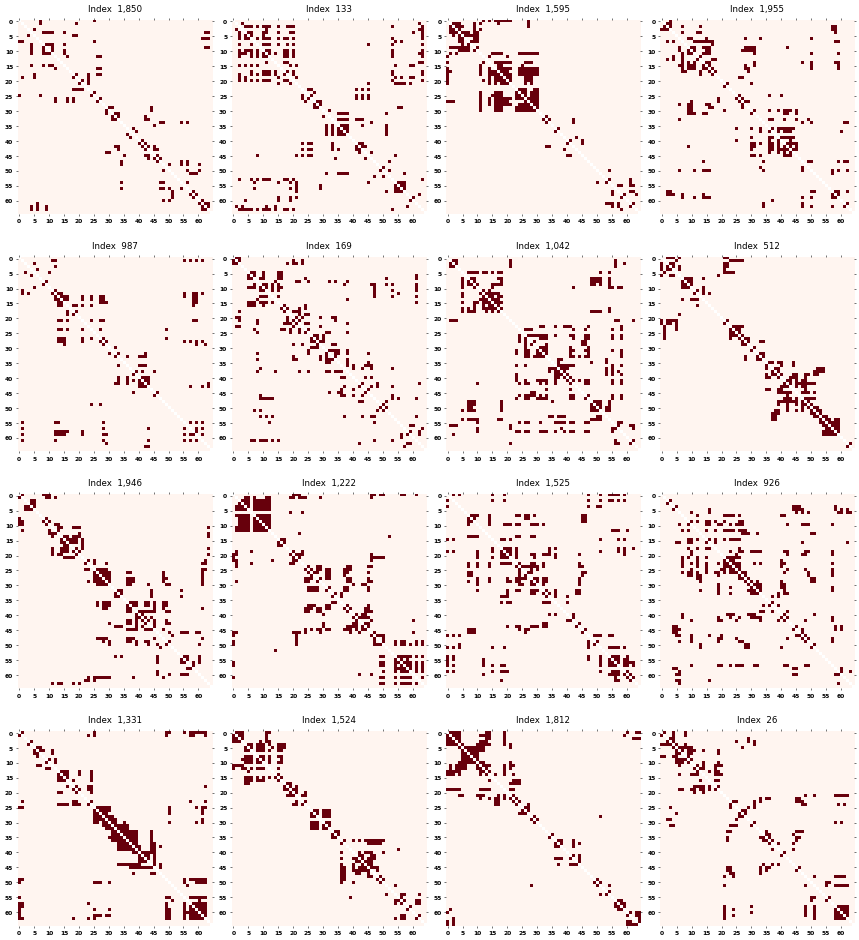

In [11]:
fig = data.plot_random_examples(num_items=16,
                                random_seed=None,
                                form="square",
                                include_cbar=False)
fig.set_dpi(48)
fig.show()

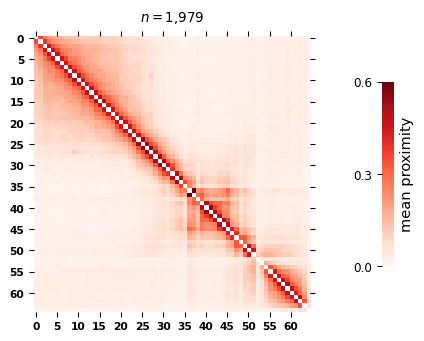

In [12]:
fig = data.plot_ensemble_measure(method="mean", form="square", cbar_label="mean proximity")
fig.set_dpi(96)
fig.show()

In [2]:
dir_results = "../../../../temp/results/example"

In [5]:
!topic3d runall \
    --data_train_file "../../../../temp/data/sample_exp.csv" \
    --results_dir "../../../../temp/results/example" \
    --proximity_threshold 200 \
    --save_proximity_data \
    --num_CFMs 10 \
    --max_iter 100 \
    --evaluate_learning

2026-03-24 14:03:06,678 [INFO] --------------------------------------------------
2026-03-24 14:03:06,678 [INFO] [56905d] Results and logs will be saved to: /mnt/grey/DATA/users/gautham/Workspace/dev/topic3d/temp/results/example
2026-03-24 14:03:06,678 [INFO] Settings summary for run: 56905d
2026-03-24 14:03:06,678 [INFO]       data_train_file: ../../../../temp/data/sample_exp.csv
2026-03-24 14:03:06,678 [INFO]       data_test_file: None
2026-03-24 14:03:06,678 [INFO]       save_proximity_data: True
2026-03-24 14:03:06,678 [INFO]       model_file: None
2026-03-24 14:03:06,679 [INFO]       results_dir: ../../../../temp/results/example
2026-03-24 14:03:06,679 [INFO]       params_file: None
2026-03-24 14:03:06,679 [INFO]       proximity_threshold: 200
2026-03-24 14:03:06,679 [INFO]       proximity_hardness: 1
2026-03-24 14:03:06,679 [INFO]       num_CFMs: 10
2026-03-24 14:03:06,679 [INFO]       max_iter: 100
2026-03-24 14:03:06,679 [INFO]       random_state: None
2026-03-24 14:03:06,679 [

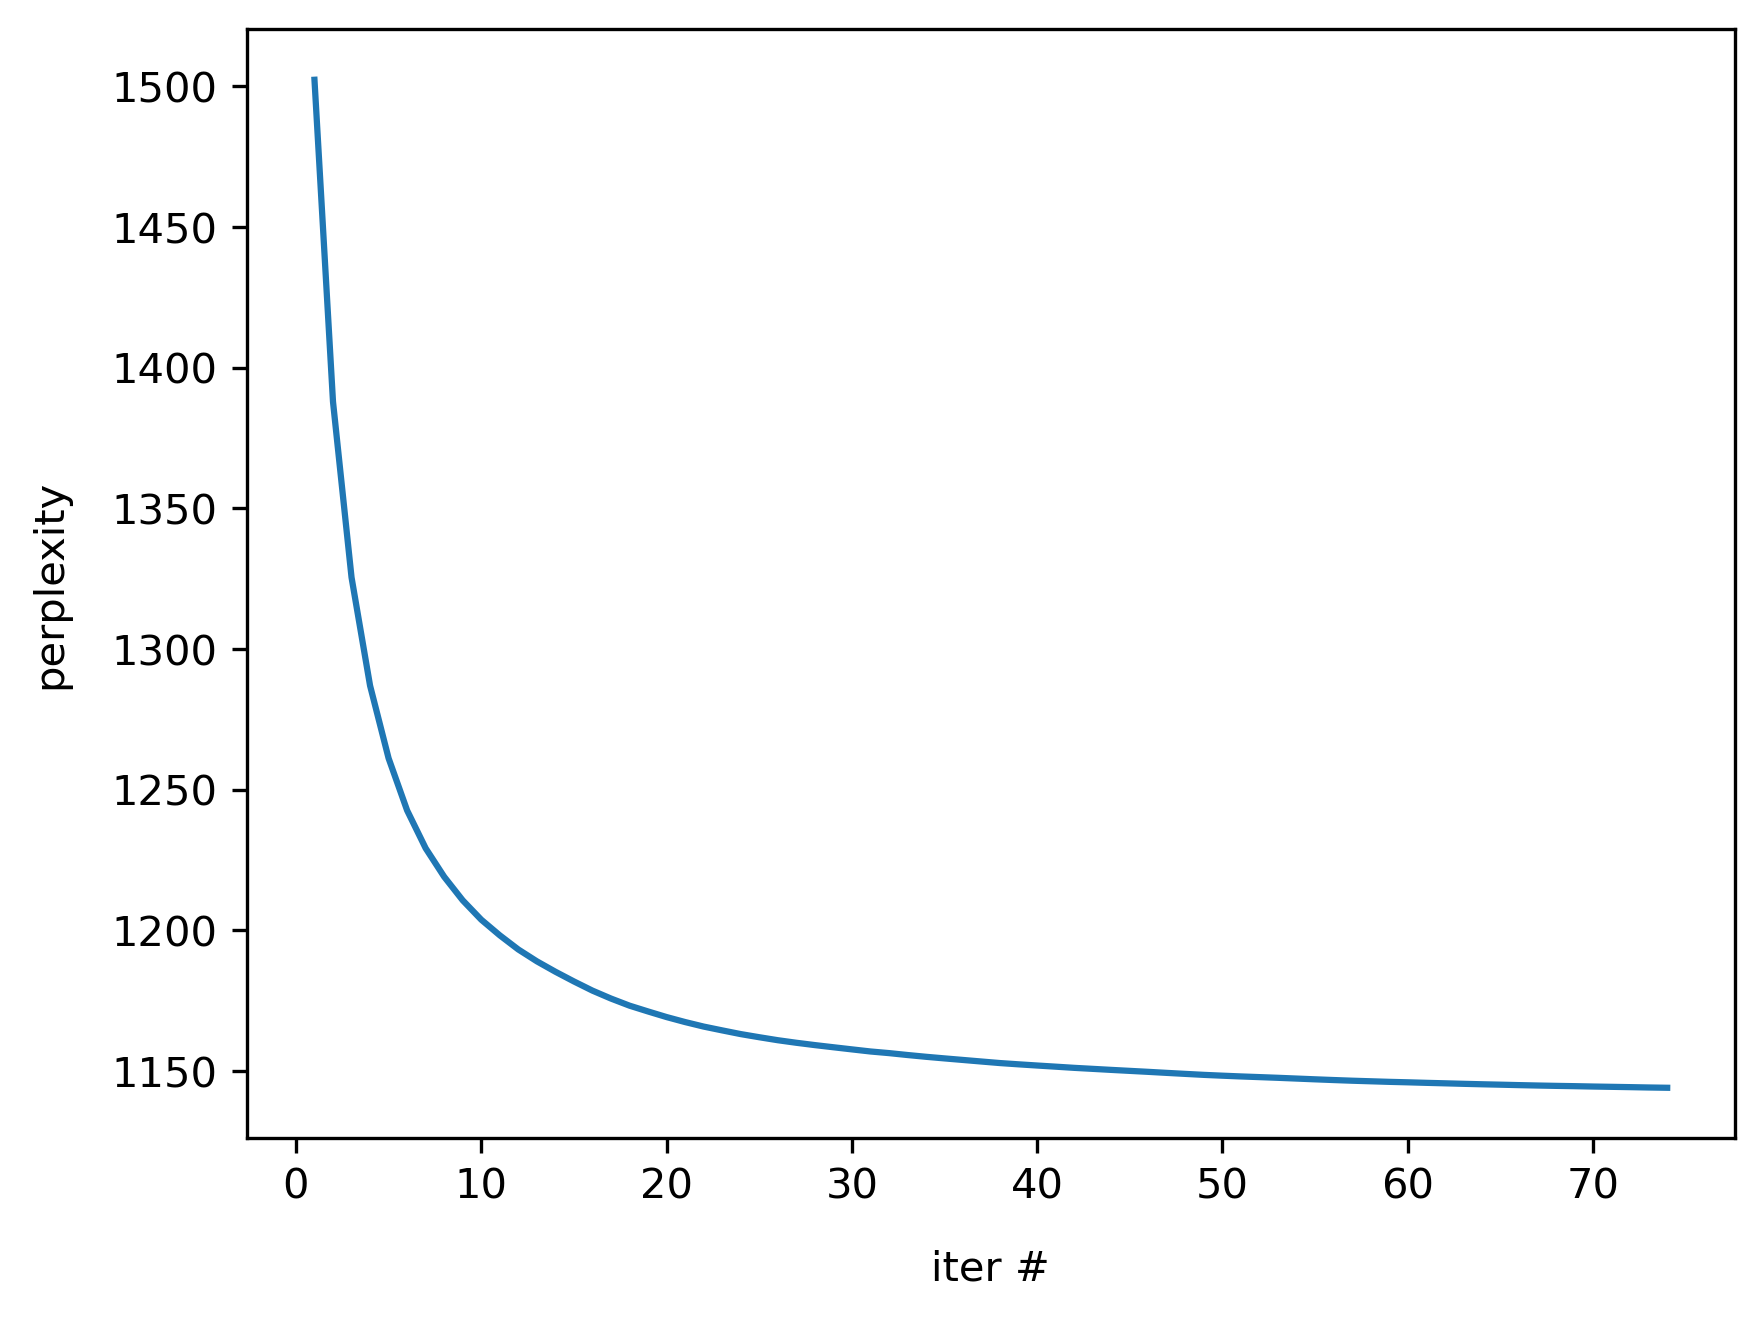

In [6]:
Image(filename=path.join(dir_results, "perplexity_evolution.png"))

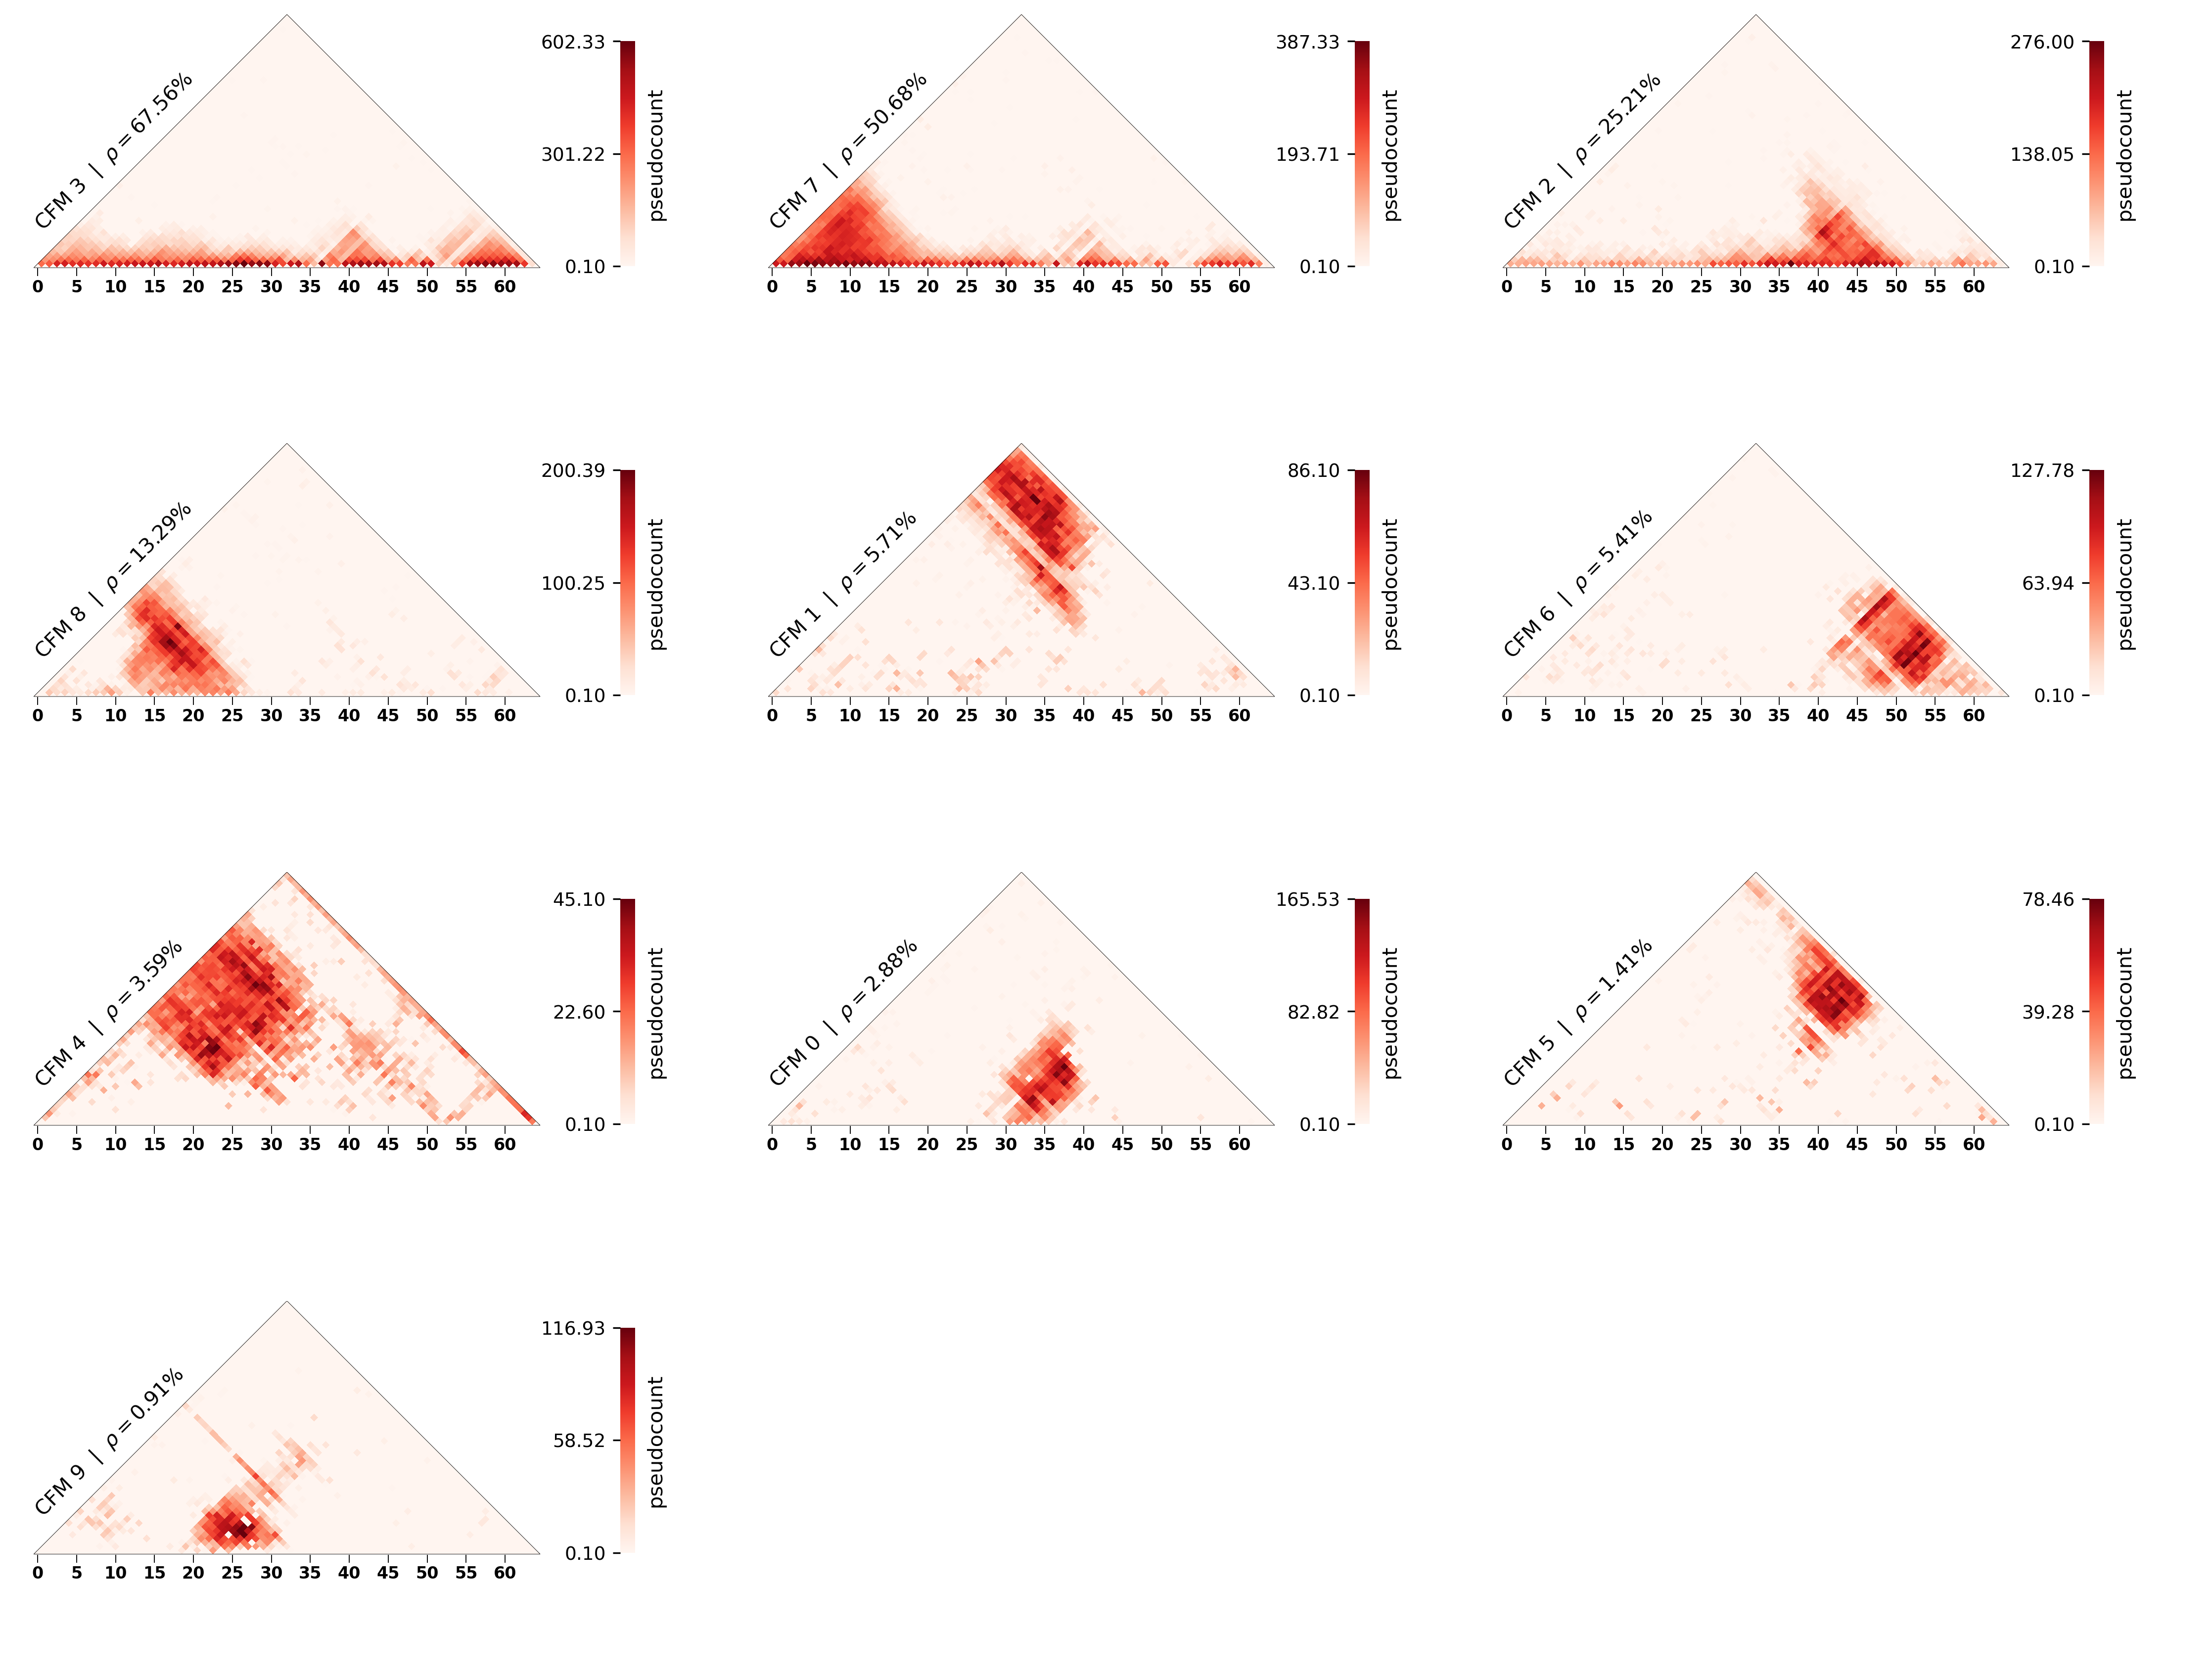

In [7]:
Image(filename=path.join(dir_results, "CFMs_ordered.png"))

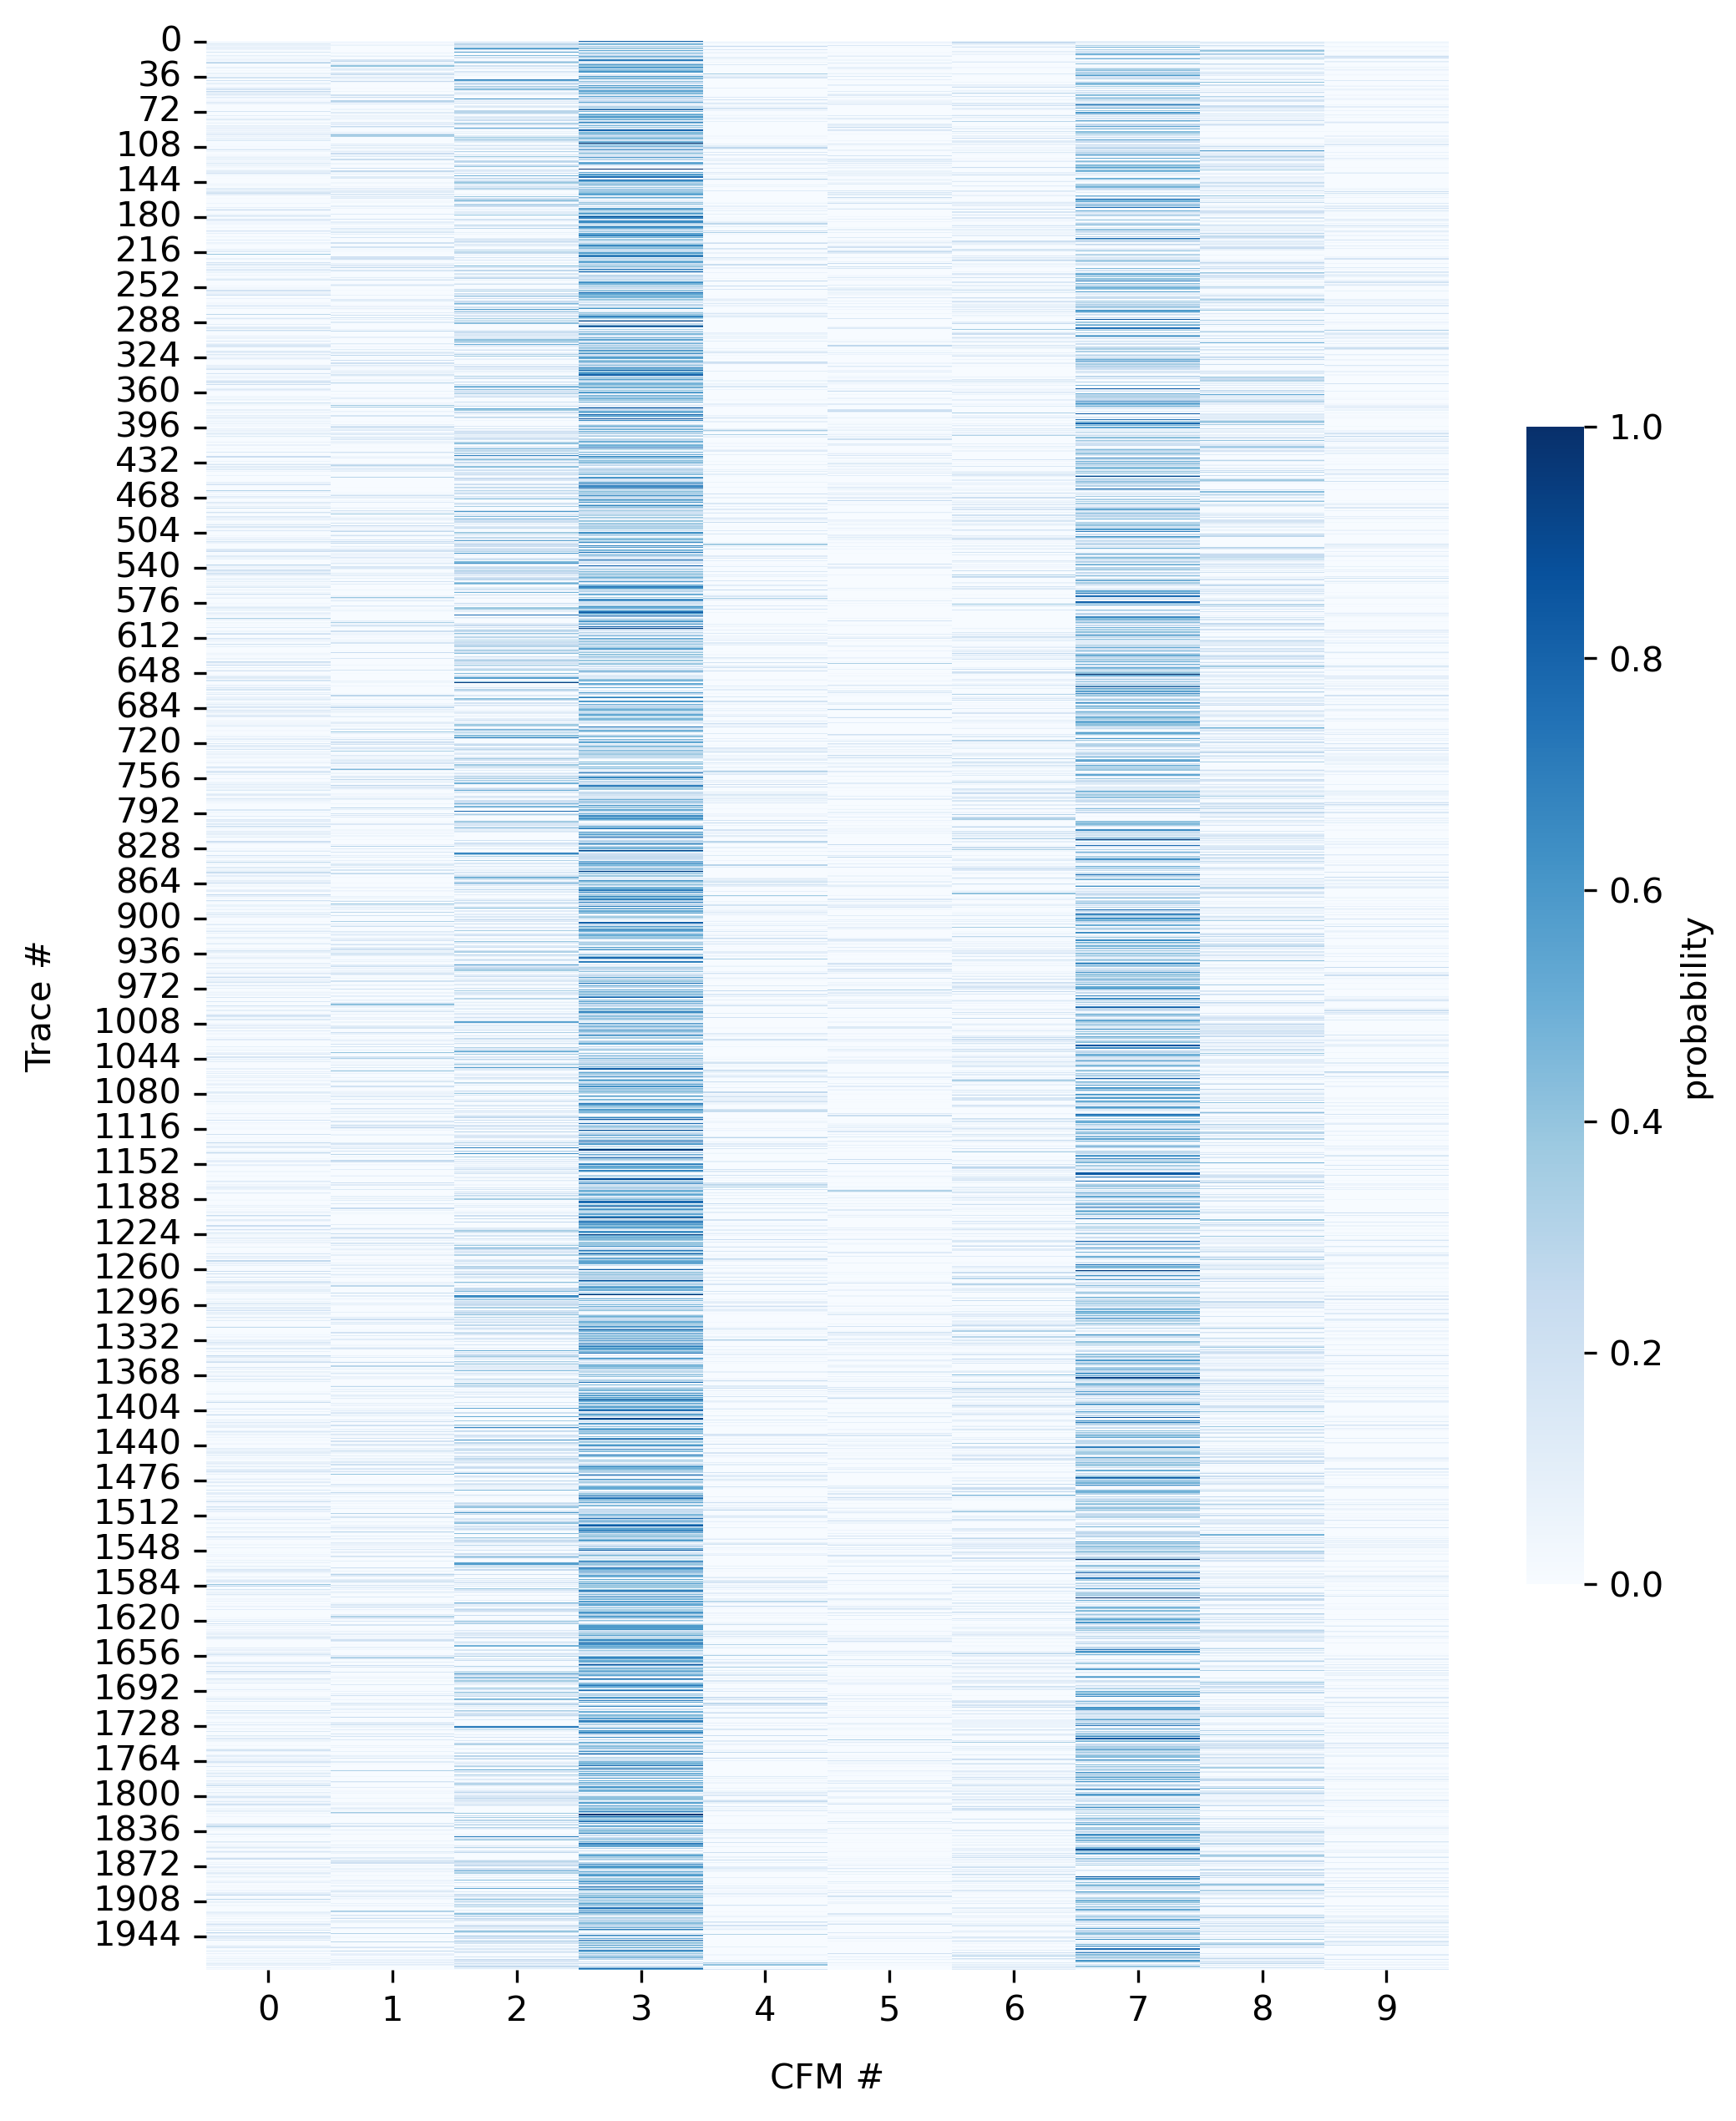

In [8]:
Image(filename=path.join(dir_results, "decomposition.png"))

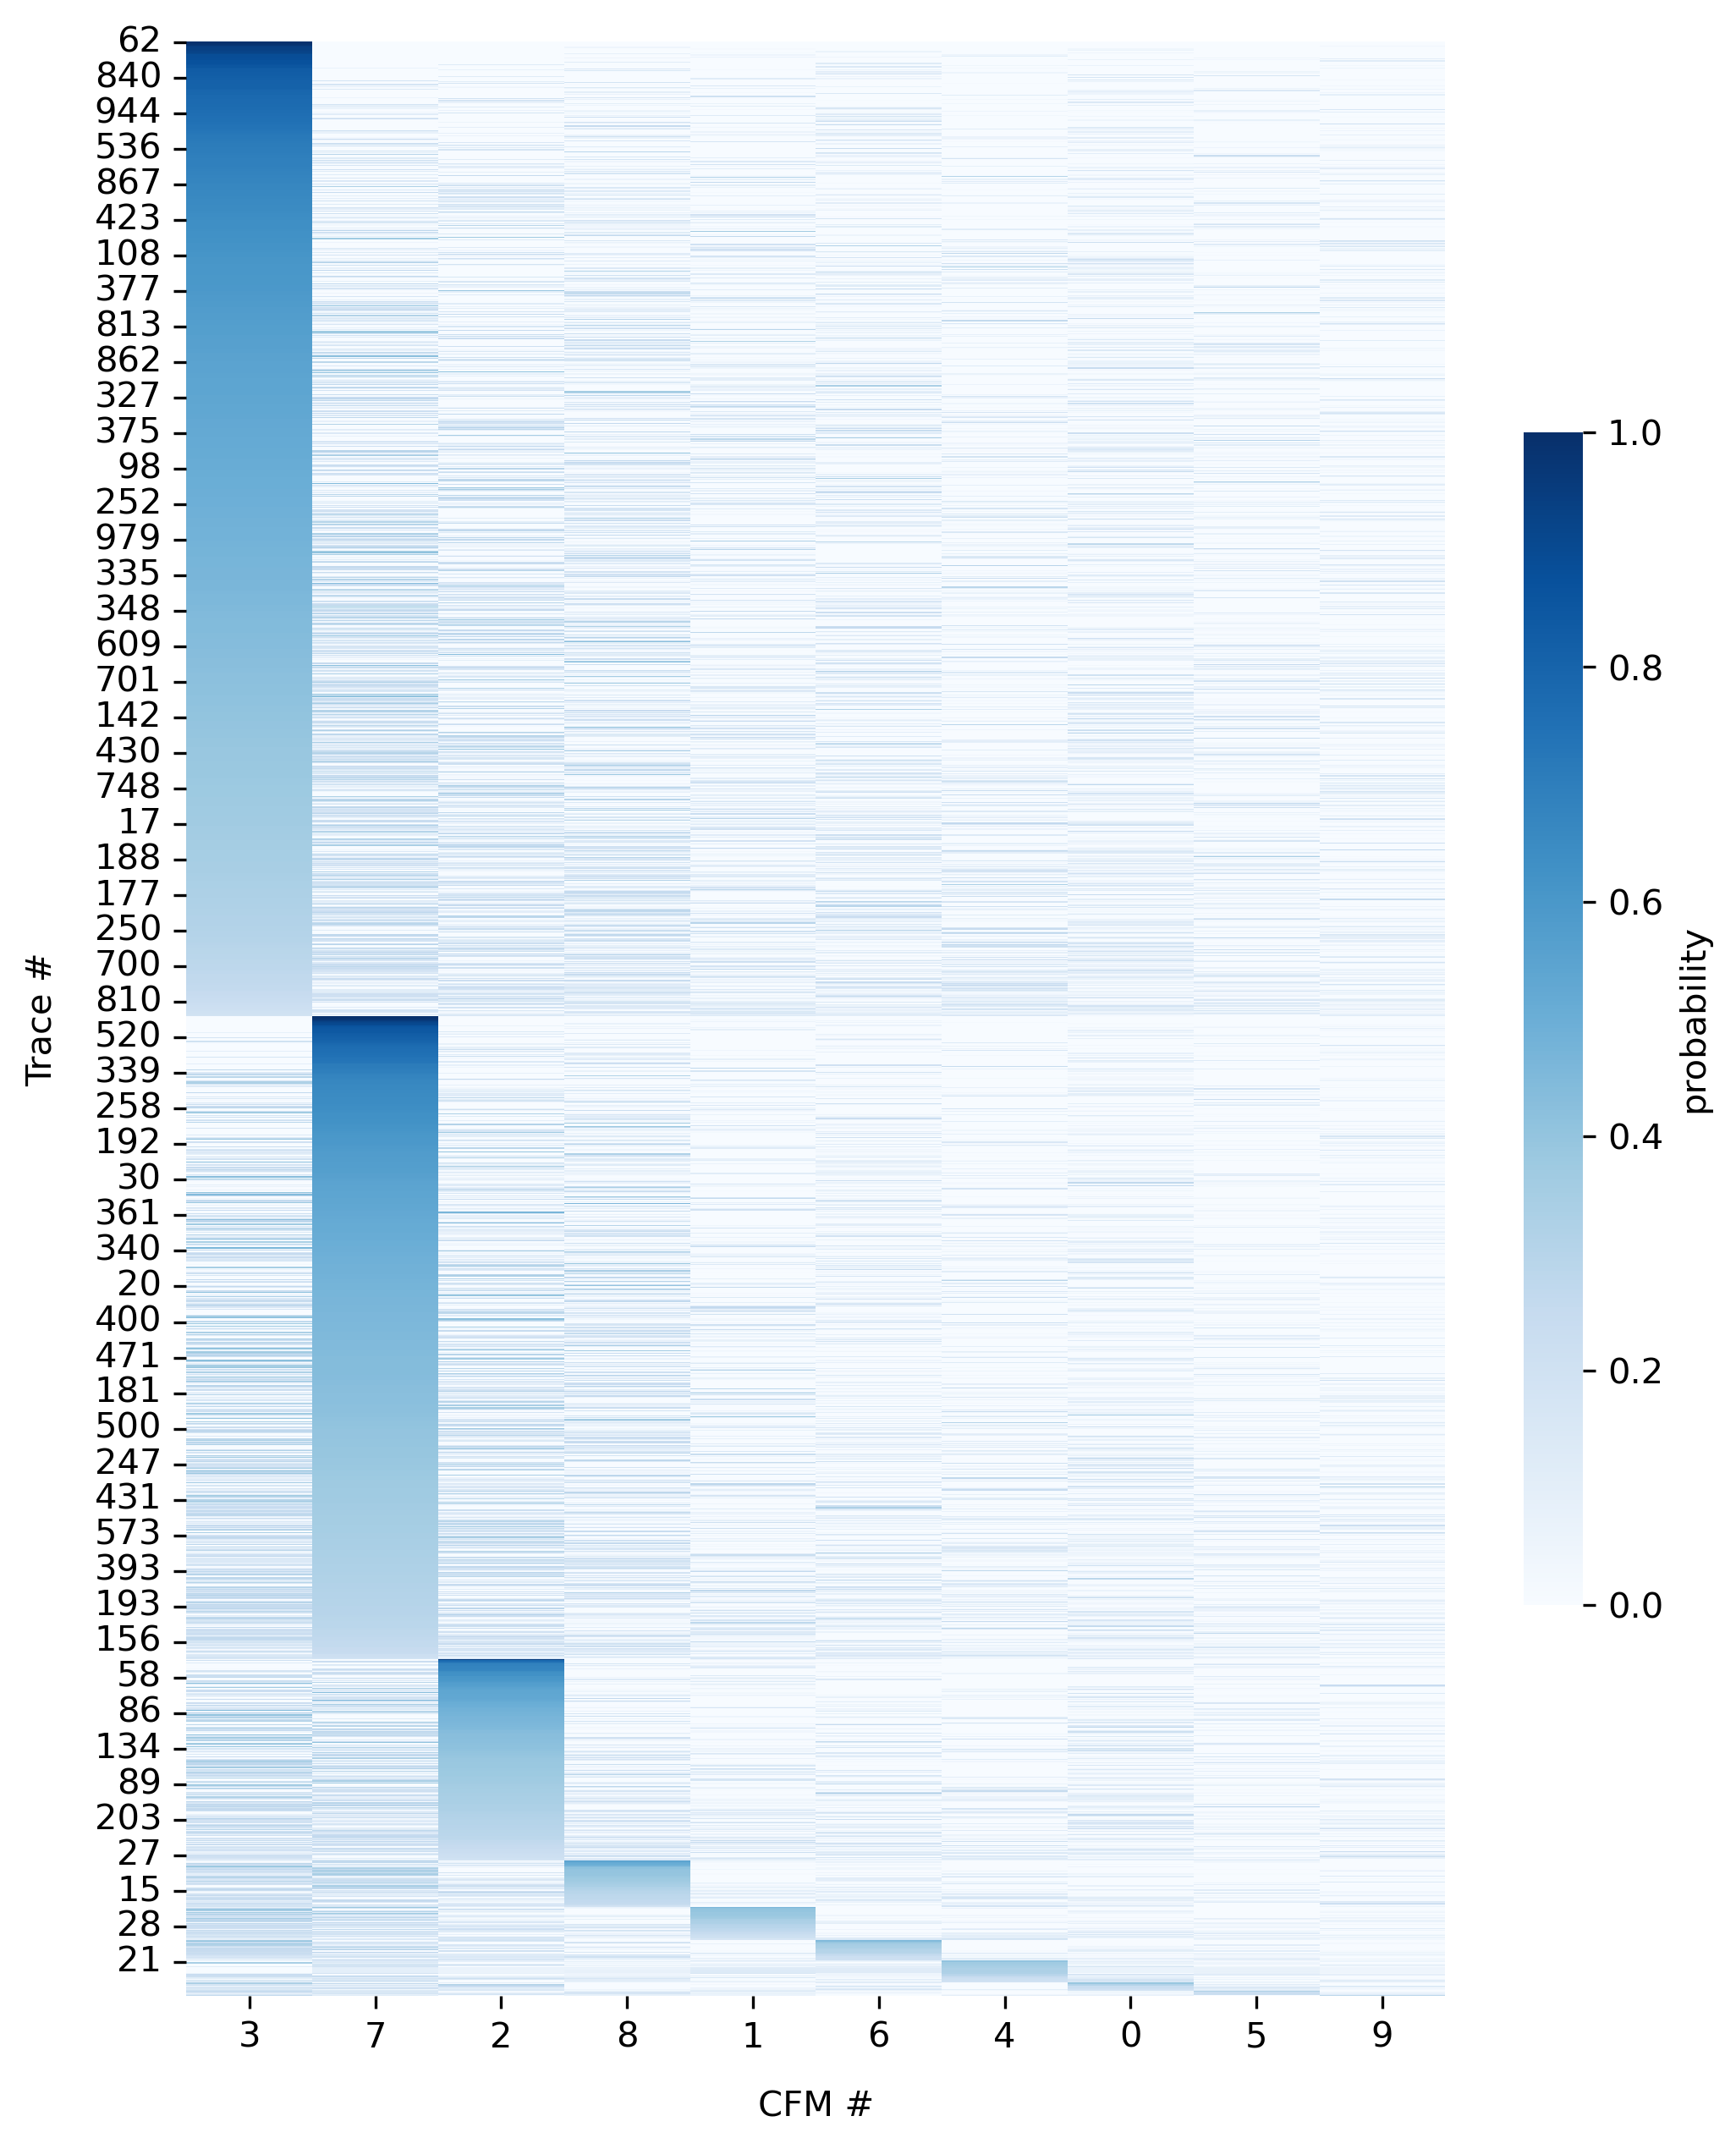

In [9]:
Image(filename=path.join(dir_results, "decomposition_ordered.png"))

## Interpreting results

After training, the model produces:

- Topic distributions per cell
- Topic–word distributions (proximity patterns)

These can be used to:
- Identify structural states
- Compare conditions (e.g. WT vs perturbation)
- Visualize embeddings


## Next steps

- Apply the workflow to experimental datasets
- Tune hyperparameters (number of topics, iterations)
- Explore downstream analysis tools in `topic3d`
